In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, ExtraTreesClassifier,
                              AdaBoostClassifier, HistGradientBoostingClassifier)

RANDOM_STATE = 42
LABELS = {1: "Fatal", 2: "Serious", 3: "Slight"}

In [2]:
from pathlib import Path

# Resolve the raw data files from the project root, even when Jupyter starts
# with the notebooks folder as its working directory.
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "data" / "raw").is_dir():
    PROJECT_DIR = next((parent for parent in Path.cwd().parents if (parent / "data" / "raw").is_dir()), PROJECT_DIR)
DATA_DIR = PROJECT_DIR / "data" / "raw"
CSV_COLLISION = DATA_DIR / "dft-road-casualty-statistics-collision-1979-latest-published-year.csv"
CSV_VEHICLE   = DATA_DIR / "dft-road-casualty-statistics-vehicle-1979-latest-published-year.csv"
CSV_CASUALTY  = DATA_DIR / "dft-road-casualty-statistics-casualty-1979-latest-published-year.csv"

MIN_YEAR = 2019


def read_filtered(path, cols, keep_ids=None, min_year=None):
    parts = []
    for chunk in pd.read_csv(path, usecols=cols, chunksize=500_000):
        if min_year is not None:
            chunk = chunk[chunk["collision_year"] >= min_year]
        if keep_ids is not None:
            chunk = chunk[chunk["collision_index"].isin(keep_ids)]
        parts.append(chunk)
    return pd.concat(parts, ignore_index=True)

In [3]:
collision_cols = [
    "collision_index", "collision_year", "collision_severity", "number_of_vehicles",
    "date", "day_of_week", "time", "first_road_class", "road_type", "speed_limit",
    "junction_detail", "junction_control", "pedestrian_crossing", "light_conditions",
    "weather_conditions", "road_surface_conditions", "urban_or_rural_area", "trunk_road_flag",
]

collisions = read_filtered(CSV_COLLISION, collision_cols, min_year=MIN_YEAR)
keep_ids = set(collisions["collision_index"])
print(collisions.shape)

(722536, 18)


In [4]:
vehicles = read_filtered(CSV_VEHICLE, ["collision_index", "vehicle_type", "age_of_driver"], keep_ids)

vehicles["age_of_driver"] = vehicles["age_of_driver"].where(vehicles["age_of_driver"] >= 0)  # -1 means missing

# flag each vehicle type, then add them up per collision
vt = vehicles["vehicle_type"]
vehicles["n_motorcycles"] = vt.isin([2, 3, 4, 5, 23, 97]).astype(int)
vehicles["n_cars"]        = (vt == 9).astype(int)
vehicles["n_vans"]        = (vt == 19).astype(int)
vehicles["n_hgv"]         = vt.isin([20, 21, 98]).astype(int)
vehicles["n_buses"]       = vt.isin([10, 11]).astype(int)
vehicles["n_cyclists"]    = (vt == 1).astype(int)

vehicle_summary = vehicles.groupby("collision_index").agg(
    n_motorcycles=("n_motorcycles", "sum"),
    n_cars=("n_cars", "sum"),
    n_vans=("n_vans", "sum"),
    n_hgv=("n_hgv", "sum"),
    n_buses=("n_buses", "sum"),
    n_cyclists=("n_cyclists", "sum"),
    youngest_driver=("age_of_driver", "min"),
    oldest_driver=("age_of_driver", "max"),
).reset_index()
print(vehicle_summary.shape)

(722536, 9)


In [5]:
casualty_cols = ["collision_index", "casualty_class", "sex_of_casualty", "age_of_casualty"]
casualties = read_filtered(CSV_CASUALTY, casualty_cols, keep_ids)

casualties["age_of_casualty"] = casualties["age_of_casualty"].where(casualties["age_of_casualty"] >= 0)

casualties["is_pedestrian"] = (casualties["casualty_class"] == 3).astype(int)
casualties["is_male"]       = (casualties["sex_of_casualty"] == 1).astype(int)
casualties["is_female"]     = (casualties["sex_of_casualty"] == 2).astype(int)
casualties["is_child"]      = ((casualties["age_of_casualty"] < 16) & casualties["age_of_casualty"].notna()).astype(int)

casualty_summary = casualties.groupby("collision_index").agg(
    n_casualties=("casualty_class", "size"),
    n_pedestrian_casualties=("is_pedestrian", "sum"),
    n_male_casualties=("is_male", "sum"),
    n_female_casualties=("is_female", "sum"),
    n_child_casualties=("is_child", "sum"),
    youngest_casualty=("age_of_casualty", "min"),
    oldest_casualty=("age_of_casualty", "max"),
).reset_index()
print(casualty_summary.shape)

CASUALTY_FEATURES = [c for c in casualty_summary.columns if c != "collision_index"]

(722536, 8)


In [6]:
df = collisions.merge(vehicle_summary, on="collision_index", how="left")
df = df.merge(casualty_summary, on="collision_index", how="left")

print(df.shape)
assert len(df) == len(collisions)

(722536, 33)


In [7]:
cols_to_clean = [c for c in df.columns if c != "junction_control"]
df[cols_to_clean] = df[cols_to_clean].replace(-1, np.nan)

for col in ["junction_detail", "pedestrian_crossing"]:
    df[col] = df[col].replace(99, np.nan)

(df.isna().mean() * 100).sort_values(ascending=False).head(10)

trunk_road_flag            7.339288
oldest_driver              5.164033
youngest_driver            5.164033
pedestrian_crossing        3.948731
junction_detail            3.365645
youngest_casualty          1.578745
oldest_casualty            1.578745
road_surface_conditions    0.573259
speed_limit                0.013148
light_conditions           0.004982
dtype: float64

In [8]:
df["hour"]         = pd.to_datetime(df["time"], format="%H:%M", errors="coerce").dt.hour
df["month"]        = pd.to_datetime(df["date"], format="%d/%m/%Y", errors="coerce").dt.month
df["is_weekend"]   = df["day_of_week"].isin([1, 7]).astype(int)      # 1 = Sunday, 7 = Saturday
RUSH_HOURS = [7, 8, 9, 16, 17, 18]
df["is_rush_hour"] = df["hour"].isin(RUSH_HOURS).astype(int)

df = df.drop(columns=["date", "time"])
df.shape

(722536, 35)

collision_severity
3    0.766
2    0.219
1    0.015
Name: proportion, dtype: float64


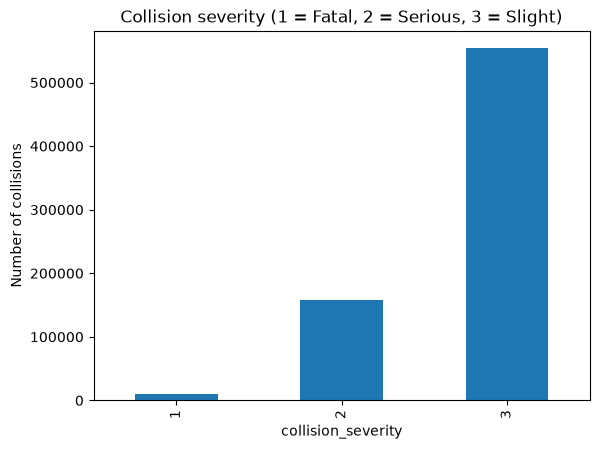

In [9]:
print(df["collision_severity"].value_counts(normalize=True).round(3))

df["collision_severity"].value_counts().sort_index().plot(kind="bar")
plt.title("Collision severity (1 = Fatal, 2 = Serious, 3 = Slight)")
plt.ylabel("Number of collisions")
plt.show()

In [10]:
# Keep later years completely out of training so the test reflects future-year predictions.
# Select the model on 2023, tune its Fatal threshold on 2024, and reserve 2025 for final evaluation.
USE_CASUALTY_FEATURES = False
TRAIN_THROUGH_YEAR = 2022
VALIDATION_YEAR = 2023
THRESHOLD_YEAR = 2024
TEST_YEAR = 2025

y = df["collision_severity"]
year = df["collision_year"]
drop_cols = ["collision_severity", "collision_index", "collision_year"]
if not USE_CASUALTY_FEATURES:
    drop_cols += CASUALTY_FEATURES
X = df.drop(columns=drop_cols).fillna(-1)

train_mask = year <= TRAIN_THROUGH_YEAR
val_mask = year == VALIDATION_YEAR
threshold_mask = year == THRESHOLD_YEAR
test_mask = year == TEST_YEAR
if not train_mask.any() or not val_mask.any() or not threshold_mask.any() or not test_mask.any():
    raise ValueError("Expected training years through 2022, validation year 2023, threshold-tuning year 2024, and test year 2025; check the dataset years.")

X_train, y_train = X.loc[train_mask], y.loc[train_mask]
X_val, y_val = X.loc[val_mask], y.loc[val_mask]
X_threshold, y_threshold = X.loc[threshold_mask], y.loc[threshold_mask]
X_test, y_test = X.loc[test_mask], y.loc[test_mask]
print("Train years:", int(year.loc[train_mask].min()), "to", int(year.loc[train_mask].max()), X_train.shape)
print("Validation year:", VALIDATION_YEAR, X_val.shape)
print("Threshold-tuning year:", THRESHOLD_YEAR, X_threshold.shape)
print("Final test year:", TEST_YEAR, X_test.shape)


Train years: 2019 to 2022 (415826, 25)
Validation year: 2023 (104258, 25)
Threshold-tuning year: 2024 (100927, 25)
Final test year: 2025 (101525, 25)


In [11]:
# Use a large but bounded training sample for model comparison; compare candidates on 2023 only.
X_small = X_train.sample(min(200_000, len(X_train)), random_state=RANDOM_STATE)
y_small = y_train.loc[X_small.index]

def tree(depth, **kw):
    return DecisionTreeClassifier(max_depth=depth, class_weight="balanced", random_state=RANDOM_STATE, **kw)

models = {
    "Decision Tree (baseline)": tree(10),
    "Bagging (accuracy)": BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=15, min_samples_leaf=20, random_state=RANDOM_STATE), n_estimators=30, n_jobs=1, random_state=RANDOM_STATE),
    "Random Forest (balanced)": RandomForestClassifier(n_estimators=100, max_depth=15, min_samples_leaf=20, class_weight="balanced", n_jobs=2, random_state=RANDOM_STATE),
    "Extra Trees (balanced)": ExtraTreesClassifier(n_estimators=100, max_depth=15, min_samples_leaf=20, class_weight="balanced", n_jobs=2, random_state=RANDOM_STATE),
    "AdaBoost (accuracy)": AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE), n_estimators=100, random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(max_iter=200, class_weight="balanced", random_state=RANDOM_STATE),
}

results = []
trained = {}
val_predictions = {}
for name, model in models.items():
    print("Training", name, "...")
    model.fit(X_small, y_small)
    pred = model.predict(X_val)
    trained[name] = model
    val_predictions[name] = pred
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_val, pred),
        "macro_f1": f1_score(y_val, pred, average="macro"),
    })

results_df = pd.DataFrame(results)
results_df_macro_f1 = results_df.sort_values("macro_f1", ascending=False).reset_index(drop=True)
results_df_macro_f1


Training Decision Tree (baseline) ...
Training Bagging (accuracy) ...
Training Random Forest (balanced) ...
Training Extra Trees (balanced) ...
Training AdaBoost (accuracy) ...
Training Hist Gradient Boosting ...


,model,accuracy,macro_f1
0,Random Forest (balanced),0.561281,0.389970
1,Extra Trees (balanced),0.573289,0.383965
2,Hist Gradient Boosting,0.548591,0.381716
3,Decision Tree (baseline),0.515855,0.364127
4,Bagging (accuracy),0.766205,0.331863
5,AdaBoost (accuracy),0.763414,0.322528


In [12]:
results_df_accuracy_score = results_df.sort_values("accuracy", ascending=False).reset_index(drop=True)
results_df_accuracy_score

,model,accuracy,macro_f1
0,Bagging (accuracy),0.766205,0.331863
1,AdaBoost (accuracy),0.763414,0.322528
2,Extra Trees (balanced),0.573289,0.383965
3,Random Forest (balanced),0.561281,0.389970
4,Hist Gradient Boosting,0.548591,0.381716
5,Decision Tree (baseline),0.515855,0.364127


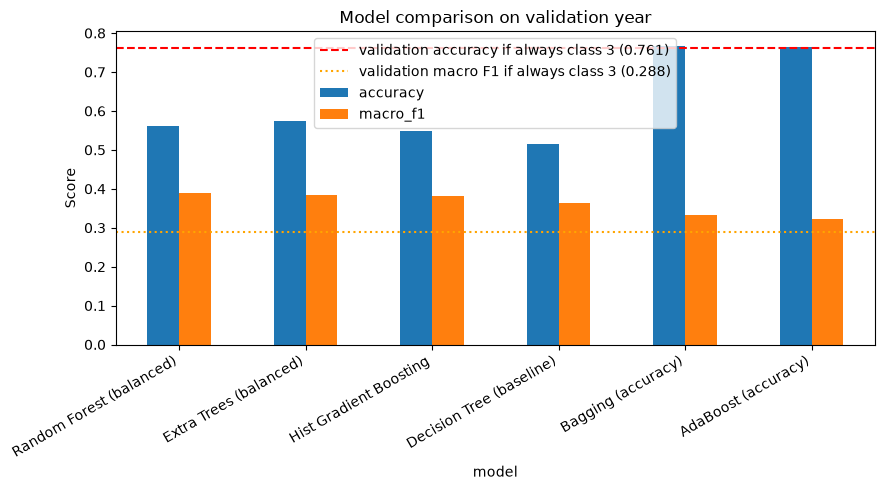

In [13]:
# Candidate scores are from validation (2024); show its majority-class baseline for comparison.
majority_class = y_train.value_counts().idxmax()
val_majority_pred = np.full(len(y_val), majority_class)
base_val_acc = accuracy_score(y_val, val_majority_pred)
base_val_f1 = f1_score(y_val, val_majority_pred, average="macro")

ax = results_df_macro_f1.set_index("model")[["accuracy", "macro_f1"]].plot(kind="bar", figsize=(9, 5))
ax.axhline(base_val_acc, color="red", linestyle="--", label=f"validation accuracy if always class {majority_class} ({base_val_acc:.3f})")
ax.axhline(base_val_f1, color="orange", linestyle=":", label=f"validation macro F1 if always class {majority_class} ({base_val_f1:.3f})")
plt.title("Model comparison on validation year")
plt.ylabel("Score")
plt.xticks(rotation=30, ha="right")
plt.legend()
plt.tight_layout()
plt.show()


In [14]:
# Select candidates on 2023 only. Tune the Fatal probability threshold on 2024,
# then report final performance once on the untouched 2025 test year.
best_f1_name = results_df_macro_f1.loc[0, "model"]
best_f1_model = trained[best_f1_name]
best_acc_name = results_df.sort_values("accuracy", ascending=False).iloc[0]["model"]
best_acc_model = trained[best_acc_name]
best_f1_model.selection_name_ = best_f1_name
best_acc_model.selection_name_ = best_acc_name

fatal_class = 1
fatal_col = list(best_f1_model.classes_).index(fatal_class)
threshold_prob = best_f1_model.predict_proba(X_threshold)
nonfatal_cols = [i for i, cls in enumerate(best_f1_model.classes_) if cls != fatal_class]
nonfatal_choice = best_f1_model.classes_[nonfatal_cols][np.argmax(threshold_prob[:, nonfatal_cols], axis=1)]
threshold_results = []
for threshold in np.arange(0.05, 0.96, 0.01):
    threshold_pred = np.where(threshold_prob[:, fatal_col] >= threshold, fatal_class, nonfatal_choice)
    threshold_results.append((f1_score(y_threshold, threshold_pred, average="macro"), threshold, threshold_pred))
_, fatal_threshold, _ = max(threshold_results, key=lambda item: item[0])
best_f1_model.fatal_threshold_ = float(fatal_threshold)

# Apply the tuned threshold consistently to held-out 2025 predictions.
def predict_with_fatal_threshold(model, X_input):
    probabilities = model.predict_proba(X_input)
    classes = np.asarray(model.classes_)
    fatal_index = list(classes).index(1)
    other_indices = [i for i, cls in enumerate(classes) if cls != 1]
    other_prediction = classes[other_indices][np.argmax(probabilities[:, other_indices], axis=1)]
    return np.where(probabilities[:, fatal_index] >= model.fatal_threshold_, 1, other_prediction)

best_f1_pred = predict_with_fatal_threshold(best_f1_model, X_test)
best_acc_pred = best_acc_model.predict(X_test)
print("Selected by 2023 macro F1:", best_f1_name)
print("Fatal threshold chosen on 2024:", round(fatal_threshold, 2))
print("2025 test report (threshold-tuned macro-F1 model):")
print(classification_report(y_test, best_f1_pred, labels=[1, 2, 3], target_names=list(LABELS.values()), zero_division=0))
print("2025 test report (validation accuracy winner):", best_acc_name)
print(classification_report(y_test, best_acc_pred, labels=[1, 2, 3], target_names=list(LABELS.values()), zero_division=0))
print("2025 test macro F1, tuned model:", round(f1_score(y_test, best_f1_pred, average="macro"), 3))
print("2025 test Fatal precision/recall:", classification_report(y_test, best_f1_pred, labels=[1, 2, 3], output_dict=True, zero_division=0)["1"]["precision"], classification_report(y_test, best_f1_pred, labels=[1, 2, 3], output_dict=True, zero_division=0)["1"]["recall"])


Selected by 2023 macro F1: Random Forest (balanced)
Fatal threshold chosen on 2024: 0.61
2025 test report (threshold-tuned macro-F1 model):
              precision    recall  f1-score   support

       Fatal       0.10      0.16      0.13      1453
     Serious       0.34      0.60      0.44     25191
      Slight       0.83      0.60      0.70     74881

    accuracy                           0.60    101525
   macro avg       0.42      0.46      0.42    101525
weighted avg       0.70      0.60      0.62    101525

2025 test report (validation accuracy winner): Bagging (accuracy)
              precision    recall  f1-score   support

       Fatal       0.00      0.00      0.00      1453
     Serious       0.54      0.07      0.13     25191
      Slight       0.75      0.98      0.85     74881

    accuracy                           0.74    101525
   macro avg       0.43      0.35      0.33    101525
weighted avg       0.69      0.74      0.66    101525

2025 test macro F1, tuned model:

[[  233   979   241]
 [  838 15226  9127]
 [ 1196 28573 45112]]


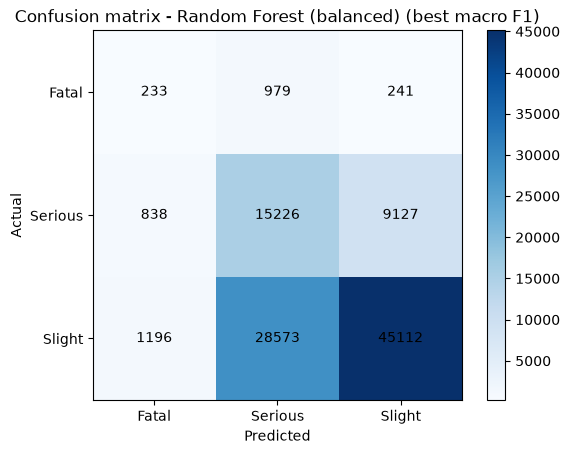

[[    0   232  1221]
 [    0  1841 23350]
 [    0  1314 73567]]


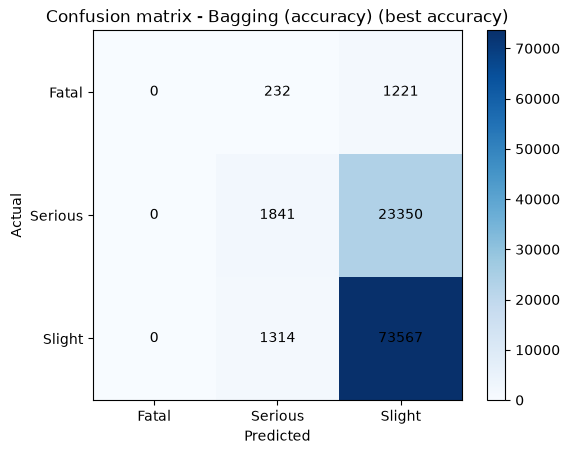

In [15]:
def plot_confusion(y_true, pred, title):
    cm = confusion_matrix(y_true, pred)
    print(cm)
    plt.figure()
    plt.imshow(cm, cmap="Blues")
    plt.colorbar()
    plt.xticks([0, 1, 2], list(LABELS.values()))
    plt.yticks([0, 1, 2], list(LABELS.values()))
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(title)
    for i in range(3):
        for j in range(3):
            plt.text(j, i, cm[i, j], ha="center", va="center")
    plt.show()

plot_confusion(y_test, best_f1_pred,  "Confusion matrix - " + best_f1_name + " (best macro F1)")
plot_confusion(y_test, best_acc_pred, "Confusion matrix - " + best_acc_name + " (best accuracy)")

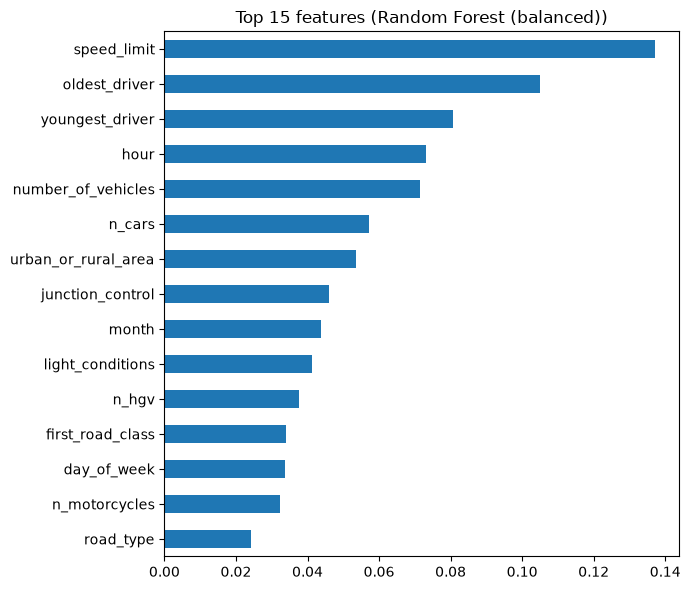

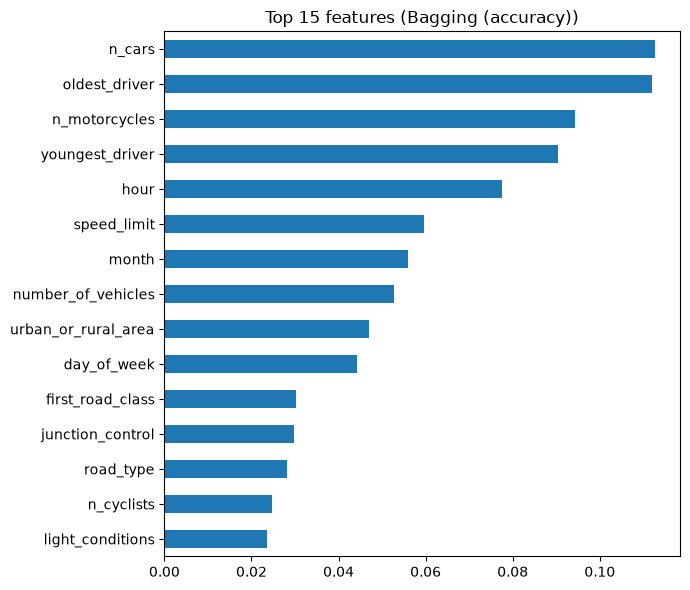

In [16]:
def get_importances(model, columns):
    if hasattr(model, "feature_importances_"):
        values = model.feature_importances_
    elif hasattr(model, "estimators_"):
        values = np.mean([est.feature_importances_ for est in model.estimators_], axis=0)
    else:
        return None
    return pd.Series(values, index=columns).sort_values(ascending=False)

for name in ["Random Forest (balanced)", "Bagging (accuracy)"]:
    imp = get_importances(trained[name], X.columns)
    imp.head(15).sort_values().plot(kind="barh", figsize=(7, 6))
    plt.title(f"Top 15 features ({name})")
    plt.tight_layout()
    plt.show()

In [17]:
sample = X_test.sample(10, random_state=1)
check = pd.DataFrame({
    "actual":    y_test.loc[sample.index].map(LABELS),
    "predicted": pd.Series(predict_with_fatal_threshold(best_f1_model, sample), index=sample.index).map(LABELS),
})
check

,actual,predicted
617742,Slight,Fatal
526000,Serious,Serious
194609,Serious,Serious
195368,Slight,Serious
535900,Slight,Serious
51299,Slight,Serious
432170,Slight,Slight
359809,Serious,Serious
266702,Serious,Serious
298135,Slight,Serious


In [18]:
# Demonstration only: make a realistic example row from training-data medians.
new_accident = X_train.median().to_frame().T
new_accident["speed_limit"] = 50
new_accident["number_of_vehicles"] = 2
new_accident["n_motorcycles"] = 1
new_accident["n_cars"] = 1
new_accident["light_conditions"] = 6
new_accident["hour"] = 23
new_accident["is_rush_hour"] = int(23 in RUSH_HOURS)
new_accident["urban_or_rural_area"] = 2

pred = predict_with_fatal_threshold(best_f1_model, new_accident)[0]
print("Model:", best_f1_name, "(Fatal threshold", round(best_f1_model.fatal_threshold_, 2), ")")
print("Predicted severity:", LABELS[pred])
probs = best_f1_model.predict_proba(new_accident)[0]
for cls, probability in zip(best_f1_model.classes_, probs):
    print(LABELS[cls], round(probability, 3))


Model: Random Forest (balanced) (Fatal threshold 0.61 )
Predicted severity: Serious
Fatal 0.383
Serious 0.384
Slight 0.233


In [19]:
# Optional diagnostic CV on the historical training sample; the year-based holdouts above remain the final evaluation.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
scores = cross_val_score(best_f1_model, X_small, y_small, cv=cv, scoring="f1_macro")
print(best_f1_name, "training-sample CV macro F1:", scores.round(3), "average:", scores.mean().round(3))


Random Forest (balanced) training-sample CV macro F1: [0.388 0.387 0.392] average: 0.389


In [20]:
sample = X_test.sample(10, random_state=1)
check = pd.DataFrame({
    "actual":    y_test.loc[sample.index].map(LABELS),
    "predicted": pd.Series(predict_with_fatal_threshold(best_f1_model, sample), index=sample.index).map(LABELS),
})
check

,actual,predicted
617742,Slight,Fatal
526000,Serious,Serious
194609,Serious,Serious
195368,Slight,Serious
535900,Slight,Serious
51299,Slight,Serious
432170,Slight,Slight
359809,Serious,Serious
266702,Serious,Serious
298135,Slight,Serious


In [21]:
sample = X_test.sample(10, random_state=1)
check = pd.DataFrame({
    "actual":    y_test.loc[sample.index].map(LABELS),
    "predicted": pd.Series(best_acc_model.predict(sample), index=sample.index).map(LABELS),
})
check

,actual,predicted
617742,Slight,Slight
526000,Serious,Slight
194609,Serious,Slight
195368,Slight,Slight
535900,Slight,Slight
51299,Slight,Slight
432170,Slight,Slight
359809,Serious,Slight
266702,Serious,Slight
298135,Slight,Slight


In [22]:
# start from the average row so every column has a sensible value
new_accident = X.median().to_frame().T

# change what you want to test (check the DfT guide for what each code means)
new_accident["speed_limit"]        = 50
new_accident["number_of_vehicles"] = 2
new_accident["n_motorcycles"]      = 1
new_accident["n_cars"]             = 1
new_accident["light_conditions"]   = 1    # darkness, no street lights
new_accident["hour"]               = 10
new_accident["urban_or_rural_area"] = 2     # rural

pred = best_acc_model.predict(new_accident)[0]
print("Model (accuracy):", best_acc_name)
print("Predicted severity:", LABELS[pred])

# probability for each class
probs = best_acc_model.predict_proba(new_accident)[0]
for cls, p in zip(best_acc_model.classes_, probs):
    print(LABELS[cls], round(p, 3))

Model (accuracy): Bagging (accuracy)
Predicted severity: Serious
Fatal 0.063
Serious 0.469
Slight 0.468


In [23]:
# Same example using the macro-F1 model and its validation-tuned Fatal threshold.
new_accident = X_train.median().to_frame().T
new_accident["speed_limit"] = 50
new_accident["number_of_vehicles"] = 2
new_accident["n_motorcycles"] = 1
new_accident["n_cars"] = 1
new_accident["light_conditions"] = 6
new_accident["hour"] = 10
new_accident["urban_or_rural_area"] = 2

pred = predict_with_fatal_threshold(best_f1_model, new_accident)[0]
print("Model (macro F1):", best_f1_name)
print("Fatal threshold:", round(best_f1_model.fatal_threshold_, 2))
print("Predicted severity:", LABELS[pred])
probs = best_f1_model.predict_proba(new_accident)[0]
for cls, probability in zip(best_f1_model.classes_, probs):
    print(LABELS[cls], round(probability, 3))


Model (macro F1): Random Forest (balanced)
Fatal threshold: 0.61
Predicted severity: Serious
Fatal 0.341
Serious 0.409
Slight 0.25


In [24]:
# from sklearn.model_selection import cross_val_score

# # Define the accuracy-selected model here too, so this cell works after a restart.
# if "best_acc_model" not in globals():
#     best_acc_name = results_df_accuracy_score.loc[0, "model"]
#     best_acc_model = trained[best_acc_name]
# scores = cross_val_score(best_acc_model, X_small, y_small, cv=cv, scoring="accuracy")
# print(best_acc_name, "accuracy CV:", scores.round(3), "average:", scores.mean().round(3))

In [25]:
# bagging_model = trained["Bagging (accuracy)"]

In [26]:
# with open("bagging_model.pkl", "wb") as file:
#     # pickle.dump(bagging_model, file)

In [27]:
from pathlib import Path
import pickle

model_dir = PROJECT_DIR / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# Keep the two validation-selected models available to Django. The macro-F1 model
# carries its validation-tuned Fatal probability threshold as fatal_threshold_.
with (model_dir / "best_macro_f1_model.pkl").open("wb") as file:
    pickle.dump(best_f1_model, file)
with (model_dir / "bagging_model.pkl").open("wb") as file:
    pickle.dump(best_acc_model, file)

print("Saved macro-F1 model:", best_f1_name, "threshold:", round(best_f1_model.fatal_threshold_, 2))
print("Saved accuracy model:", best_acc_name)
print("Final evaluation year:", TEST_YEAR)


Saved macro-F1 model: Random Forest (balanced) threshold: 0.61
Saved accuracy model: Bagging (accuracy)
Final evaluation year: 2025


In [29]:
# Optional: reload the newly saved macro-F1 model to confirm the artifact is readable.
with (model_dir / "best_macro_f1_model.pkl").open("rb") as file:
    best_model = pickle.load(file)
print("Reloaded:", type(best_model).__name__)


Reloaded: RandomForestClassifier
